# NO₂ beside a main road vs. the air nearby

Reads the database that `pipeline.py` fills. Two rules keep the comparison fair:

- compare the two sites only in **hours where both have a reading**, so a gap at one site cannot bias it
- count a **day** only if at least 18 of its 24 hours were measured

In [1]:
import duckdb

ROAD, BACKGROUND = "MY1", "GT1"            # Marylebone Road (kerbside), Station Walk (urban background)
WHO_DAILY = 25                             # WHO 2021 guideline for the 24-hour mean of NO2, µg/m³

Database = duckdb.connect("air.duckdb", read_only=True)

## 1. How much data each site has

In [2]:
Database.sql("""
    SELECT site_code,
           count(*)                         AS hours,
           count(value)                     AS hours_with_value,
           round(100 * count(value) / count(*)) AS percent_measured,
           round(avg(value), 1)             AS mean_no2
    FROM readings
    GROUP BY site_code
""").df()

,site_code,hours,hours_with_value,percent_measured,mean_no2
0,MY1,2148,1630,76.0,52.1
1,GT1,2148,2132,99.0,13.0


## 2. When is the road worst? Average by hour of day

The table is joined with itself on the hour, so each row pairs the road and the background reading for the same hour.

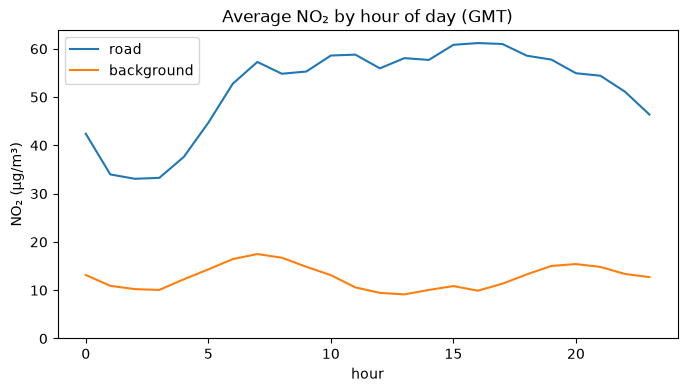

In [3]:
ByHour = Database.sql(f"""
    SELECT hour(Road.measured_at) AS hour,
           avg(Road.value)        AS road,
           avg(Background.value)  AS background
    FROM readings Road
    JOIN readings Background ON Road.measured_at = Background.measured_at
    WHERE Road.site_code = '{ROAD}' AND Background.site_code = '{BACKGROUND}'
      AND Road.value IS NOT NULL AND Background.value IS NOT NULL
    GROUP BY hour
    ORDER BY hour
""").df()

ByHour.plot(x="hour", y=["road", "background"], title="Average NO₂ by hour of day (GMT)",
            ylabel="NO₂ (µg/m³)", ylim=(0, None), figsize=(8, 4));

## 3. Day by day, against the WHO guideline

Days with too few readings are missing from the table, so they show as gaps in the lines.

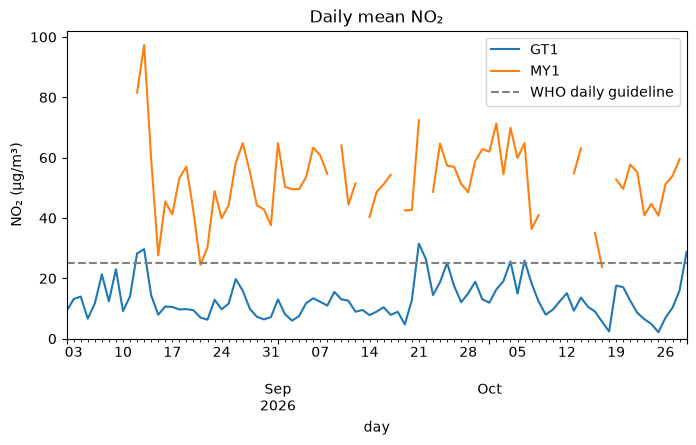

In [4]:
Daily = Database.sql("""
    SELECT measured_at::DATE AS day, site_code, avg(value) AS daily_mean
    FROM readings
    WHERE value IS NOT NULL
    GROUP BY day, site_code
    HAVING count(*) >= 18
""").df()

ByDay = Daily.pivot(index="day", columns="site_code", values="daily_mean").asfreq("D")   # one row per calendar day
Axis = ByDay.plot(title="Daily mean NO₂", ylabel="NO₂ (µg/m³)", ylim=(0, None), figsize=(8, 4))
Axis.axhline(WHO_DAILY, color="grey", linestyle="--", label="WHO daily guideline")
Axis.legend();

## 4. The headline numbers

In [5]:
Ratio = ByHour["road"].mean() / ByHour["background"].mean()
Worst = ByHour.loc[(ByHour["road"] - ByHour["background"]).idxmax()]
DaysOver = (ByDay > WHO_DAILY).sum()
DaysMeasured = ByDay.notna().sum()

print(f"Beside the road, NO2 is {Ratio:.1f}x the background level.")
print(f"The gap is largest at {int(Worst['hour']):02d}:00 GMT.")
print(f"Days above the WHO guideline: {ROAD} {DaysOver[ROAD]} of {DaysMeasured[ROAD]}, "
      f"{BACKGROUND} {DaysOver[BACKGROUND]} of {DaysMeasured[BACKGROUND]}.")

Database.close()

Beside the road, NO2 is 4.1x the background level.
The gap is largest at 16:00 GMT.
Days above the WHO guideline: MY1 67 of 69, GT1 8 of 89.
